<a href="https://colab.research.google.com/github/rama603/Final-Project---Data-Science-in-Cyber-/blob/main/Reading_Sign_Language_stage2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

# Set seed for exact reproducibility across stages
SEED = 42
np.random.seed(SEED)

# 1. Load Data
train_df = pd.read_csv("sign_mnist_train.csv")
test_df = pd.read_csv("sign_mnist_test.csv")

X_train_full = train_df.drop(columns="label").values.astype("float32") / 255.0
y_train_full = train_df["label"].values

X_test = test_df.drop(columns="label").values.astype("float32") / 255.0
y_test = test_df["label"].values

# 2. Maintain Stage 1 Data Split (e.g., 80/20 split)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=SEED, stratify=y_train_full
)

print(f"Training shape: {X_train.shape}")
print(f"Validation shape: {X_val.shape}")
print(f"Test shape: {X_test.shape}")

Training shape: (21964, 784)
Validation shape: (5491, 784)
Test shape: (7172, 784)


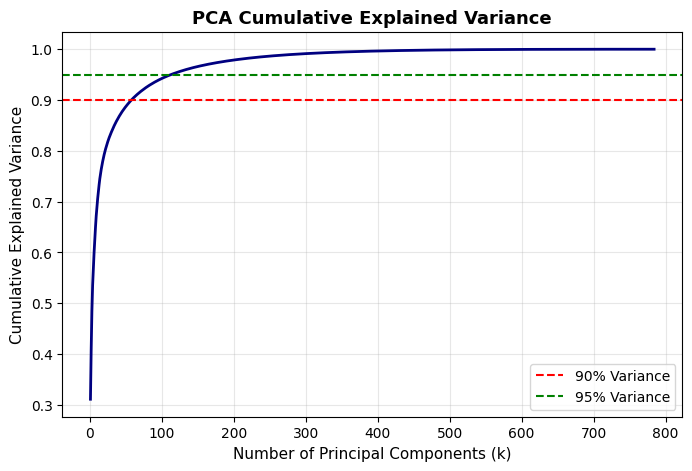

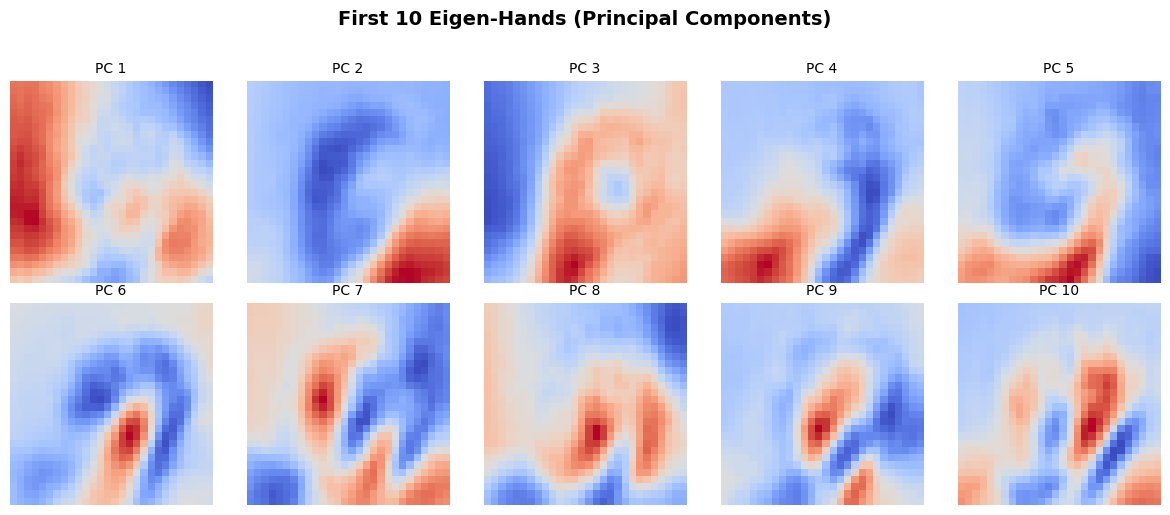

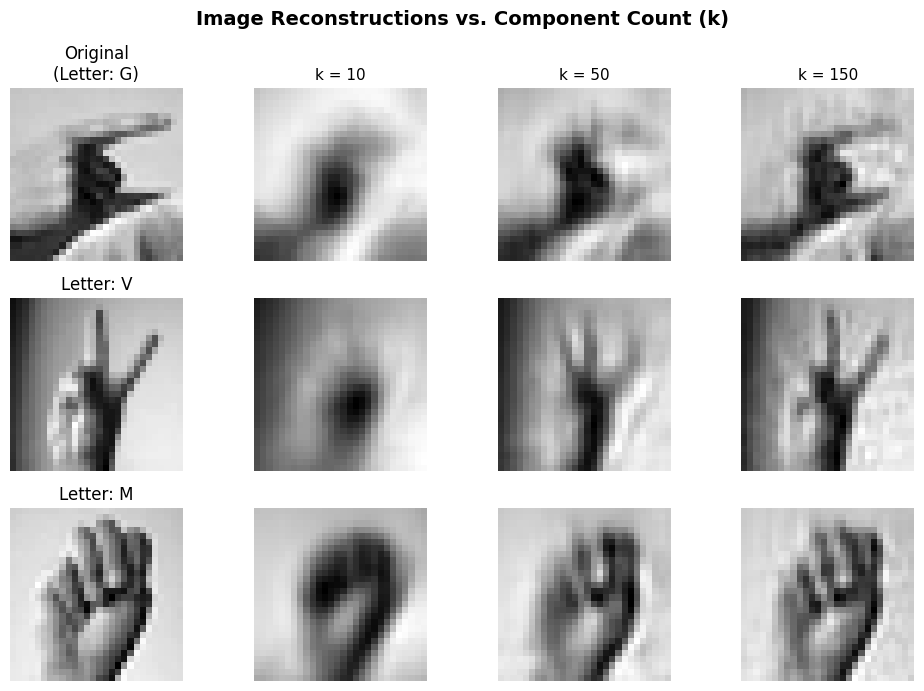

In [2]:
# 1. Fit PCA on training set only with max components (784)
pca_full = PCA(n_components=784, random_state=SEED)
pca_full.fit(X_train)

cum_explained_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Plot Cumulative Explained Variance
plt.figure(figsize=(8, 5))
plt.plot(range(1, 785), cum_explained_variance, color='navy', linewidth=2)
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Variance')
plt.axhline(y=0.95, color='g', linestyle='--', label='95% Variance')
plt.xlabel("Number of Principal Components (k)", fontsize=11)
plt.ylabel("Cumulative Explained Variance", fontsize=11)
plt.title("PCA Cumulative Explained Variance", fontsize=13, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. Display the First 10 Eigen-hands (Principal Components as 28x28 images)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    eigen_hand = pca_full.components_[i].reshape(28, 28)
    ax.imshow(eigen_hand, cmap='coolwarm')
    ax.set_title(f"PC {i+1}", fontsize=10)
    ax.axis('off')
plt.suptitle("First 10 Eigen-Hands (Principal Components)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 3. Reconstruct Sample Images from 10, 50, and 150 Components
def get_letter(label):
    label = int(label)
    if label == 9:
        return 'J'
    return chr(ord('A') + label)
sample_indices = [0, 5, 13] # Grab a few test images
k_values = [10, 50, 150]

fig, axes = plt.subplots(len(sample_indices), len(k_values) + 1, figsize=(10, 7))

for row_idx, img_idx in enumerate(sample_indices):
    orig_img = X_test[img_idx]
    true_label = y_test[img_idx]
    true_letter = get_letter(true_label)

    # Original
    axes[row_idx, 0].imshow(orig_img.reshape(28, 28), cmap='gray')
    axes[row_idx, 0].set_title(f"Original\n(Letter: {true_letter})" if row_idx == 0 else f"Letter: {true_letter}")
    axes[row_idx, 0].axis('off')
    # Reconstructions for each k
    for col_idx, k in enumerate(k_values):
        pca_k = PCA(n_components=k, random_state=SEED).fit(X_train)
        img_transformed = pca_k.transform(orig_img.reshape(1, -1))
        img_reconstructed = pca_k.inverse_transform(img_transformed).reshape(28, 28)

        axes[row_idx, col_idx + 1].imshow(img_reconstructed, cmap='gray')
        if row_idx == 0:
            axes[row_idx, col_idx + 1].set_title(f"k = {k}", fontsize=11)
        axes[row_idx, col_idx + 1].axis('off')

plt.suptitle("Image Reconstructions vs. Component Count (k)", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

Raw Pixels Baseline (784 features) -> Val Acc: 0.9995, Test Acc: 0.6973, Time: 71.88s
k =  10 | Val Acc: 0.4389 | Test Acc: 0.4056 | Fit Time: 0.93s
k =  50 | Val Acc: 0.8783 | Test Acc: 0.6893 | Fit Time: 7.01s
k = 150 | Val Acc: 0.9995 | Test Acc: 0.6694 | Fit Time: 7.21s
k = 200 | Val Acc: 0.9995 | Test Acc: 0.6842 | Fit Time: 7.98s
k = 300 | Val Acc: 0.9996 | Test Acc: 0.6956 | Fit Time: 9.98s
k = 500 | Val Acc: 0.9995 | Test Acc: 0.6926 | Fit Time: 12.31s


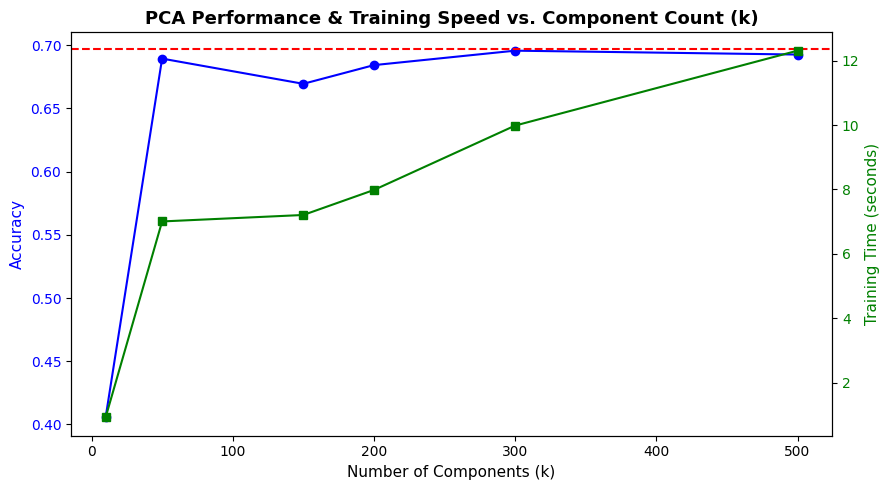

In [3]:
k_list = [10, 50, 150, 200, 300, 500]
val_accuracies = []
test_accuracies = []
training_times = []

# Baseline Stage 1 model on Raw Pixels (784 features)
start_time = time.time()
baseline_clf = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)
baseline_clf.fit(X_train, y_train)
raw_train_time = time.time() - start_time
raw_val_acc = accuracy_score(y_val, baseline_clf.predict(X_val))
raw_test_acc = accuracy_score(y_test, baseline_clf.predict(X_test))

print(f"Raw Pixels Baseline (784 features) -> Val Acc: {raw_val_acc:.4f}, Test Acc: {raw_test_acc:.4f}, Time: {raw_train_time:.2f}s")

for k in k_list:
    # Transform datasets using k components
    pca_k = PCA(n_components=k, random_state=SEED).fit(X_train)
    X_train_pca = pca_k.transform(X_train)
    X_val_pca = pca_k.transform(X_val)
    X_test_pca = pca_k.transform(X_test)

    # Train softmax classifier on PCA features
    t0 = time.time()
    clf = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)
    clf.fit(X_train_pca, y_train)
    t_elapsed = time.time() - t0

    val_acc = accuracy_score(y_val, clf.predict(X_val_pca))
    test_acc = accuracy_score(y_test, clf.predict(X_test_pca))

    val_accuracies.append(val_acc)
    test_accuracies.append(test_acc)
    training_times.append(t_elapsed)

    print(f"k = {k:3d} | Val Acc: {val_acc:.4f} | Test Acc: {test_acc:.4f} | Fit Time: {t_elapsed:.2f}s")

# Plot Accuracy vs. k
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(k_list, test_accuracies, 'b-o', label='Test Accuracy')
ax1.axhline(y=raw_test_acc, color='r', linestyle='--', label='Raw Pixels Test Acc')
ax1.set_xlabel("Number of Components (k)", fontsize=11)
ax1.set_ylabel("Accuracy", color='b', fontsize=11)
ax1.tick_params(axis='y', labelcolor='b')

# Twin axis for Training Time
ax2 = ax1.twinx()
ax2.plot(k_list, training_times, 'g-s', label='Training Time (s)')
ax2.set_ylabel("Training Time (seconds)", color='g', fontsize=11)
ax2.tick_params(axis='y', labelcolor='g')

plt.title("PCA Performance & Training Speed vs. Component Count (k)", fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()

In [4]:
# Add Gaussian noise (mean=0, std=0.2) and clip values to valid [0, 1] pixel range
NOISE_LEVEL = 0.2
X_test_noisy = np.clip(X_test + np.random.normal(0, NOISE_LEVEL, X_test.shape), 0.0, 1.0)

# 1. Test Raw Pixels Classifier on Noisy Test Set
raw_noisy_acc = accuracy_score(y_test, baseline_clf.predict(X_test_noisy))
raw_drop = (raw_test_acc - raw_noisy_acc) * 100

# 2. Select Chosen k (e.g., k=200)
chosen_k = 200
pca_chosen = PCA(n_components=chosen_k, random_state=SEED).fit(X_train)

X_train_chosen = pca_chosen.transform(X_train)
X_test_clean_chosen = pca_chosen.transform(X_test)
X_test_noisy_chosen = pca_chosen.transform(X_test_noisy)

clf_chosen = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)
clf_chosen.fit(X_train_chosen, y_train)

chosen_clean_acc = accuracy_score(y_test, clf_chosen.predict(X_test_clean_chosen))
chosen_noisy_acc = accuracy_score(y_test, clf_chosen.predict(X_test_noisy_chosen))
chosen_drop = (chosen_clean_acc - chosen_noisy_acc) * 100

print(f"--- NOISE EXPERIMENT RESULTS (Noise std={NOISE_LEVEL}) ---")
print(f"Raw Pixels (784)  -> Clean Acc: {raw_test_acc*100:.2f}% | Noisy Acc: {raw_noisy_acc*100:.2f}% | Drop: {raw_drop:.2f}%")
print(f"PCA (k={chosen_k})    -> Clean Acc: {chosen_clean_acc*100:.2f}% | Noisy Acc: {chosen_noisy_acc*100:.2f}% | Drop: {chosen_drop:.2f}%")

--- NOISE EXPERIMENT RESULTS (Noise std=0.2) ---
Raw Pixels (784)  -> Clean Acc: 69.73% | Noisy Acc: 52.57% | Drop: 17.16%
PCA (k=200)    -> Clean Acc: 68.42% | Noisy Acc: 52.20% | Drop: 16.22%


In [5]:
# Summary Table Construction
table_data = []

# Raw Pixels Entry
table_data.append({
    "Feature Representation": "Raw Pixels (784)",
    "Clean Test Accuracy (%)": f"{raw_test_acc * 100:.2f}%",
    "Training Time (s)": f"{raw_train_time:.2f}s",
    "Noisy Test Accuracy (%)": f"{raw_noisy_acc * 100:.2f}%"
})

# Entries for 10, 50, 150 components
for k in [10, 50, 150, 200, 300, 500]:
    pca_eval = PCA(n_components=k, random_state=SEED).fit(X_train)
    X_tr_p = pca_eval.transform(X_train)
    X_te_p = pca_eval.transform(X_test)
    X_te_noisy_p = pca_eval.transform(X_test_noisy)

    t0 = time.time()
    m_eval = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED).fit(X_tr_p, y_train)
    t_fit = time.time() - t0

    acc_clean = accuracy_score(y_test, m_eval.predict(X_te_p))
    acc_noisy = accuracy_score(y_test, m_eval.predict(X_te_noisy_p))

    table_data.append({
        "Feature Representation": f"PCA (k={k})",
        "Clean Test Accuracy (%)": f"{acc_clean * 100:.2f}%",
        "Training Time (s)": f"{t_fit:.2f}s",
        "Noisy Test Accuracy (%)": f"{acc_noisy * 100:.2f}%"
    })

summary_df = pd.DataFrame(table_data)
print("--- REQUIRED STAGE 2 REPORT TABLE ---")
display(summary_df)

--- REQUIRED STAGE 2 REPORT TABLE ---


,Feature Representation,Clean Test Accuracy (%),Training Time (s),Noisy Test Accuracy (%)
0,Raw Pixels (784),69.73%,71.88s,52.57%
1,PCA (k=10),40.56%,2.87s,38.36%
2,PCA (k=50),68.93%,8.98s,53.22%
3,PCA (k=150),66.94%,5.25s,51.91%
4,PCA (k=200),68.42%,7.71s,52.20%
5,PCA (k=300),69.56%,9.28s,52.38%
6,PCA (k=500),69.26%,11.85s,52.27%
